In [1]:
import os

os.environ["EXTRA_CLING_ARGS"] = "-Wno-nonportable-include-path"

import tempfile
from ctypes import c_int

import pyzx
from IPython.display import SVG, display
from ogdf_python import cppinclude, ogdf

from qelebrimbor.formats.ogdf import OGDF
from qelebrimbor.formats.pyzx import PYZX

cppinclude("ogdf/planarity/PlanRep.h")
cppinclude("ogdf/planarity/SubgraphPlanarizer.h")
cppinclude("ogdf/planarity/PlanarizationLayout.h")
cppinclude("ogdf/planarity/EmbedderMinDepthMaxFaceLayers.h")

cppinclude("ogdf/orthogonal/OrthoLayout.h")

cppinclude("ogdf/fileformats/GraphIO.h")

True

In [2]:
settings = ogdf.GraphIO.SVGSettings()
settings.fontColor("white")
settings.fontSize(8)


def print_layout(graph_attributes):
    with tempfile.NamedTemporaryFile(suffix=".svg", delete=True) as tmp:
        ogdf.GraphIO.drawSVG(graph_attributes, tmp.name, settings)
        display(SVG(tmp.name))

In [3]:
vertex_colors = {
    pyzx.VertexType.X: ogdf.Color(255, 0, 0, 255),
    pyzx.VertexType.Z: ogdf.Color(0, 0, 255, 255),
    pyzx.VertexType.BOUNDARY: ogdf.Color(64, 64, 64, 255),
}

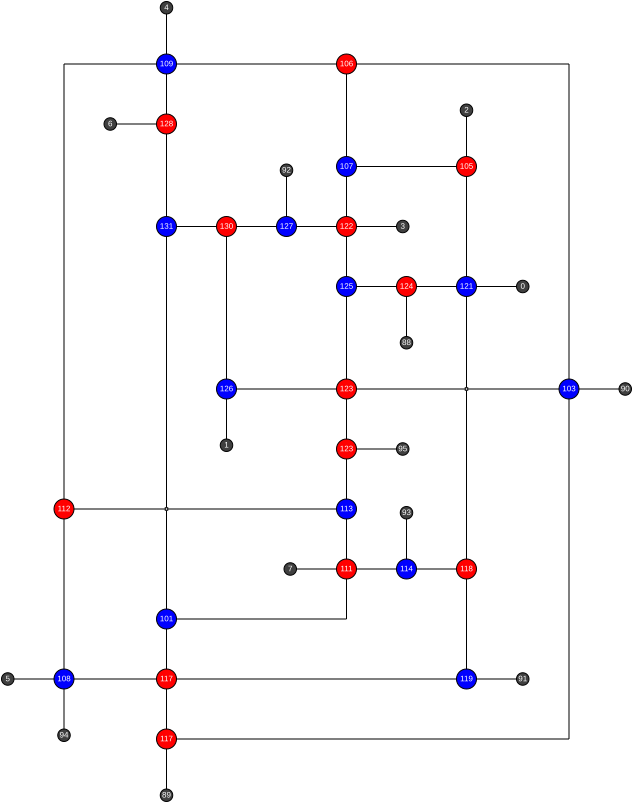

In [4]:
# Convert graph from VZX to OGDF for running layout algorithm
zxg = PYZX.from_file("../benchmarking/datasets/medio/identity/quick/random-cnots-q8-d32-s3746021966.pyzx.internal.json")
ogg, _, reverse = OGDF.from_pyzx_graph(zxg)

planarizer = ogdf.SubgraphPlanarizer()

count = c_int(0)
pr = ogdf.PlanRep(ogg)
planarizer.call(pr, 0, count)

extras_original = {}

for node in pr.nodes:
    if node.degree() <= 4:
        continue

    ordered_edges = [adj.theEdge() for adj in node.adjEntries]
    edge_count = len(ordered_edges)
    required_spiders = ((edge_count + (edge_count % 2)) // 2) - 1
    extras = [pr.newNode() for _ in range(required_spiders - 1)]
    # Connect the extras
    pr.newEdge(node, extras[0])
    for i in range(required_spiders - 2):
        pr.newEdge(extras[i], extras[i + 1])
    for idx, extra in enumerate(extras):
        # Attach edge at [3+idx] and [edge_count-1-idx] to extra
        edgeOne = ordered_edges[3 + idx]
        if edgeOne.source() == node:
            pr.moveSource(edgeOne, extra)
        else:
            pr.moveTarget(edgeOne, extra)
        edgeTwo = ordered_edges[edge_count - 1 - idx]
        if edgeTwo.source() == node:
            pr.moveSource(edgeTwo, extra)
        else:
            pr.moveTarget(edgeTwo, extra)
        extras_original[extra] = pr.original(node)

attributes = ogdf.GraphAttributes(pr, ogdf.GraphAttributes.all)

for node in pr.nodes:
    # Only style the nodes that correspond to a vertex in the original graph
    vertex: int | None = reverse.get(pr.original(node) or extras_original.get(node))
    if vertex is None:
        attributes.height[node] = 2.5
        attributes.width[node] = 2.5
    else:
        vertex_type = zxg.type(vertex)
        attributes.fillColor[node] = (
            vertex_colors[vertex_type] if vertex_type in vertex_colors else ogdf.Color(255, 255, 255, 255)
        )

        attributes.label[node] = str(vertex)
        attributes.width[node] = 12.5 if vertex_type == pyzx.VertexType.BOUNDARY else 20.0
        attributes.height[node] = 12.5 if vertex_type == pyzx.VertexType.BOUNDARY else 20.0
        attributes.shape[node] = ogdf.Shape.Ellipse

undirected = getattr(ogdf.EdgeArrow, "None")
for edge in pr.edges:
    attributes.arrowType[edge] = undirected

algorithm = ogdf.PlanarizationLayout()

layout = ogdf.OrthoLayout()
layout.__python_owns__ = False  # Needed to avoid C++ segmentation fault when object is destroyed
layout.separation(40.0)
algorithm.setPlanarLayouter(layout)

embedder = ogdf.EmbedderMinDepthMaxFaceLayers()
embedder.__python_owns__ = False
algorithm.setEmbedder(embedder)

algorithm.call(attributes)

print_layout(attributes)

Nodes : 40


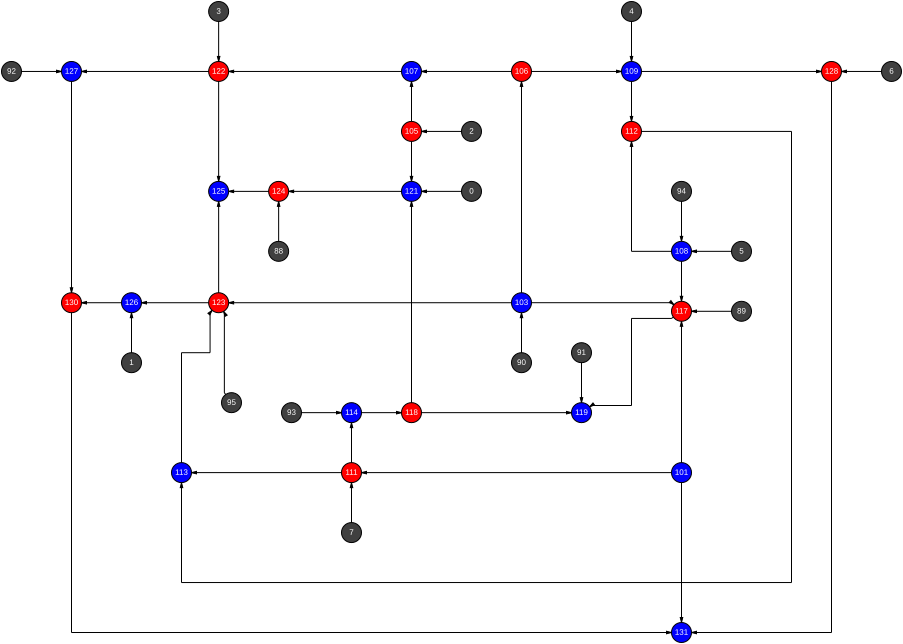

In [5]:
# Convert graph from VZX to OGDF for running layout algorithm
ogg, attributes, _ = OGDF.from_pyzx_graph(
    PYZX.from_file("../benchmarking/datasets/medio/identity/quick/random-cnots-q8-d32-s3746021966.pyzx.internal.json")
)

print(f"Nodes : {len(ogg.nodes)}")

algorithm = ogdf.PlanarizationLayout()
layout = ogdf.OrthoLayout()
layout.__python_owns__ = False  # Needed to avoid C++ segmentation fault when object is destroyed
layout.separation(40.0)
embedder = ogdf.EmbedderMinDepthMaxFaceLayers()
embedder.__python_owns__ = False
algorithm.setEmbedder(embedder)
algorithm.setPlanarLayouter(layout)

algorithm.call(attributes)

print_layout(attributes)

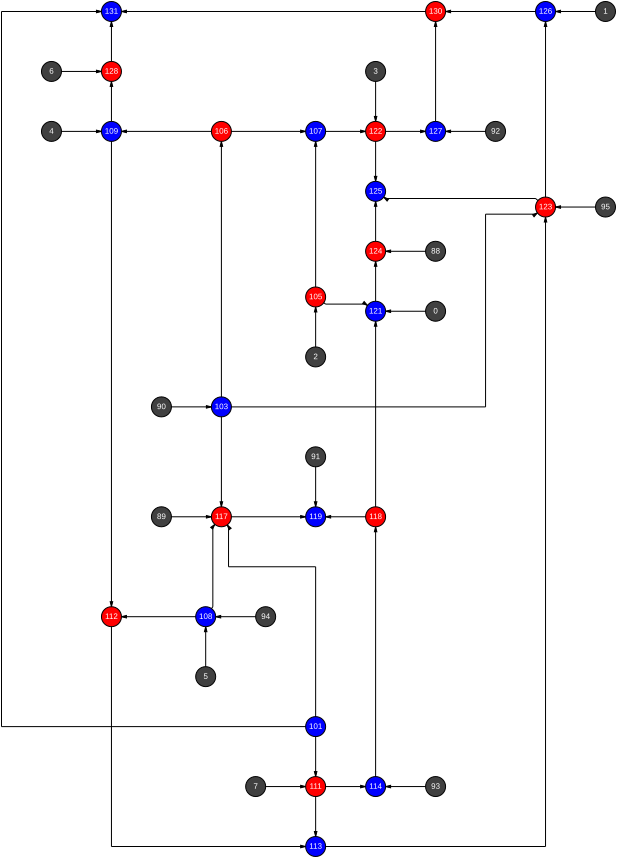

In [6]:
# Convert graph from VZX to OGDF for running layout algorithm
ogg, attributes, _ = OGDF.from_pyzx_graph(
    PYZX.from_file("../benchmarking/datasets/medio/identity/quick/random-cnots-q8-d32-s3746021966.pyzx.internal.json")
)

algorithm = ogdf.PlanarizationLayout()
layout = ogdf.OrthoLayout()
layout.separation(40.0)
layout.__python_owns__ = False  # Needed to avoid C++ segmentation fault when object is destroyed
algorithm.setPlanarLayouter(layout)

algorithm.call(attributes)

print_layout(attributes)

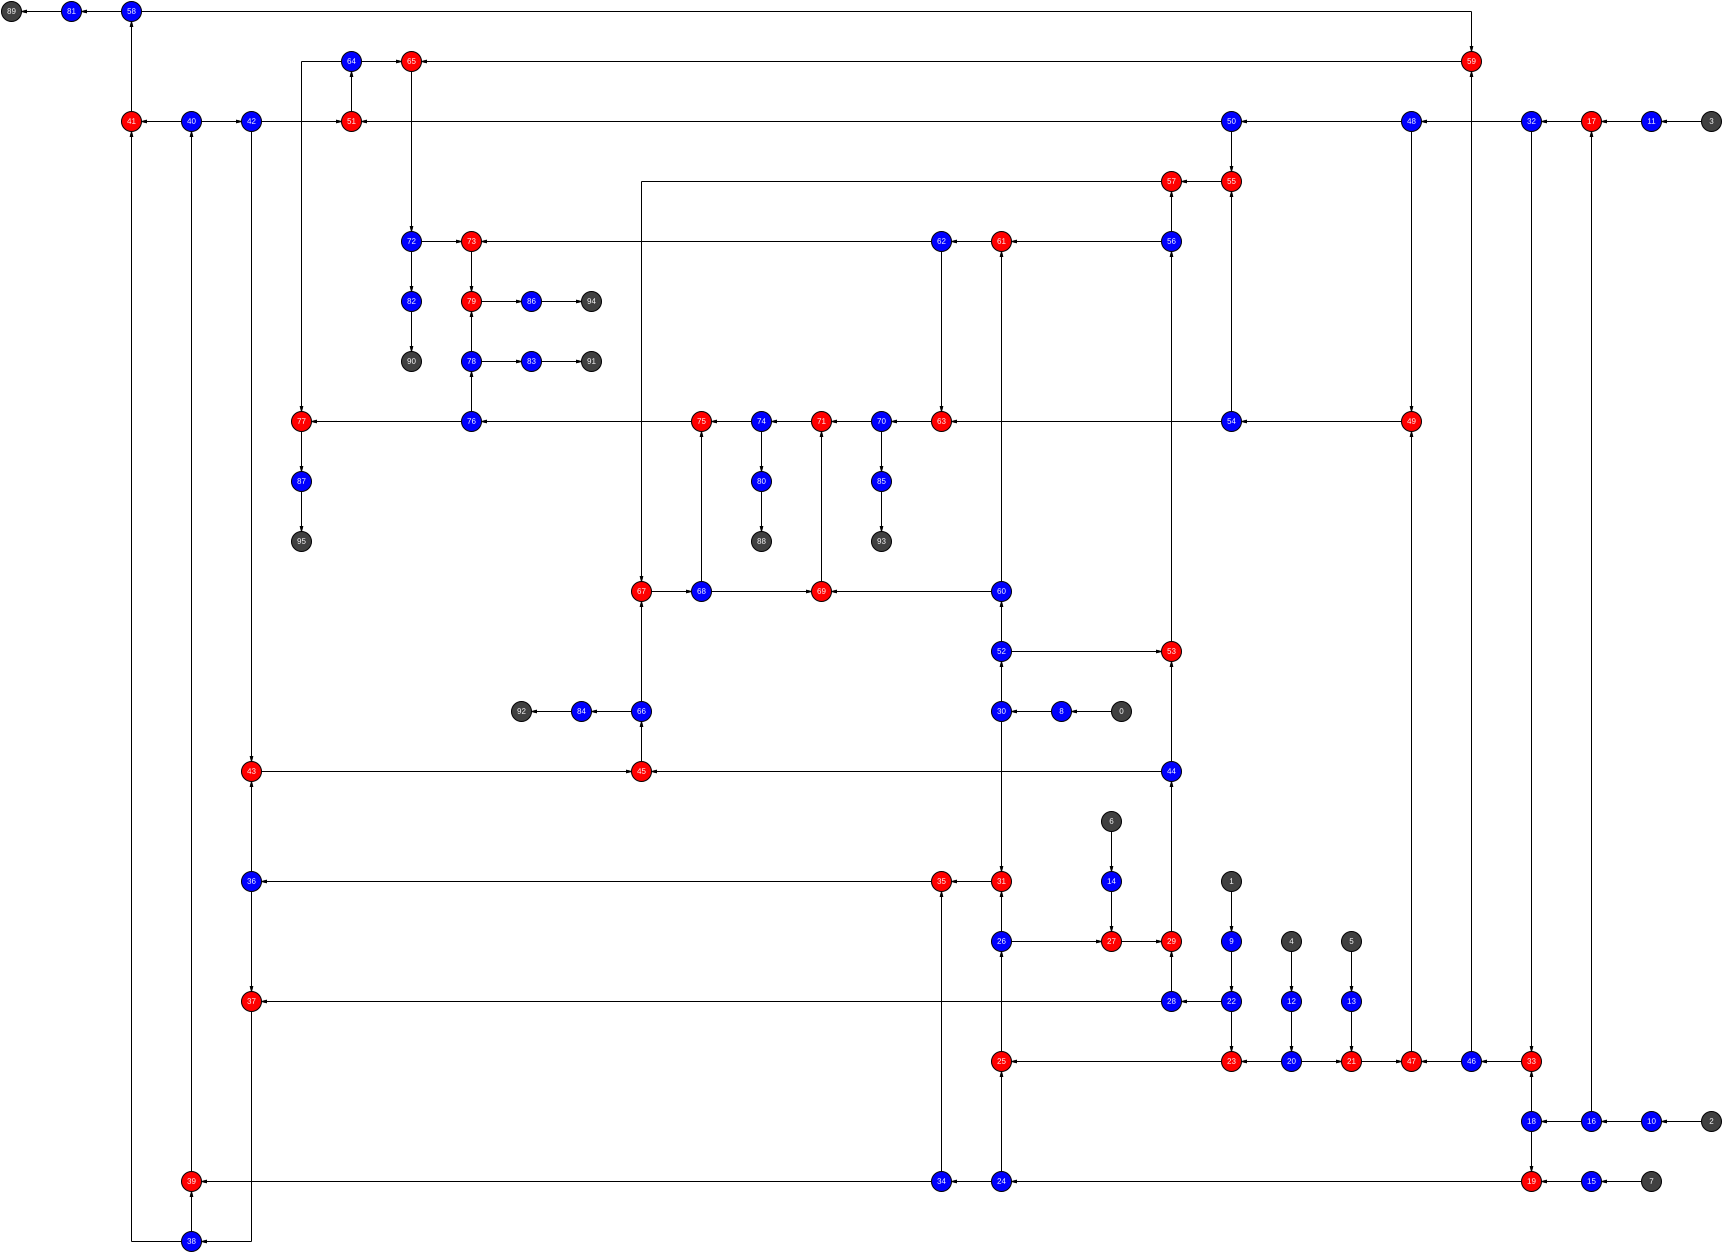

In [7]:
# Convert graph from VZX to OGDF for running layout algorithm
ogg, attributes, _ = OGDF.from_pyzx_graph(
    PYZX.from_file("../benchmarking/datasets/medio/identity/quick/random-cnots-q8-d32-s3746021966.pyzx.json")
)

algorithm = ogdf.PlanarizationLayout()
layout = ogdf.OrthoLayout()
layout.__python_owns__ = False  # Needed to avoid C++ segmentation fault when object is destroyed
layout.separation(40.0)
embedder = ogdf.EmbedderMinDepthMaxFaceLayers()
embedder.__python_owns__ = False
algorithm.setEmbedder(embedder)
algorithm.setPlanarLayouter(layout)

algorithm.call(attributes)

print_layout(attributes)